ANALYSIS OF PREMIER LEAGUE MATCH OUTCOMES

2026297, Erick Henrique da Silva, 

Github Link: https://github.com/2026297-cyber/Statistical-Techniques
Datasets: https://datahub.io/football/english-premier-league

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scipy.stats as stats
from scipy.stats import binom, poisson

In [50]:
df1  = pd.read_csv("season-2526.csv")
df2  = pd.read_csv("season-2425.csv")
df3  = pd.read_csv("season-2324.csv")
df4  = pd.read_csv("season-2223.csv")
df5  = pd.read_csv("season-2122.csv")
df6  = pd.read_csv("season-2021.csv")
df7  = pd.read_csv("season-1920.csv")
df8  = pd.read_csv("season-1819.csv")
df9  = pd.read_csv("season-1718.csv")
df10 = pd.read_csv("season-1617.csv")

df = pd.concat([df1, df2, df3, df4, df5, df6, df7, df8, df9, df10], ignore_index=True)

In [51]:
   # --- DICTIONARY ---
# FTHG = Full Time Home Goals 
# FTAG = Full Time Away Goals 
# FTR  = Full Time Result - (Home = H, Away = A, Draw = D)
# HTHG = Half Time Home Goals 
# HTAG = Half Time Away Goals 
# HTR  = Half Time Result 
# Referee = Match Referee
# HS   = Home Shots 
# AS   = Away Shots 
# HST  = Home Shots on Target 
# AST  = Away Shots on Target 
# HF   = Home Fouls 
# AF   = Away Fouls 
# HC   = Home Corners 
# AC   = Away Corners 
# HY   = Home Yellows 
# AY   = Away Yellows 
# HR   = Home Reds 
# AR   = Away Reds

---------------------------------------------------------------------------------  PART 1  ------------------------------------------------------------------------------------

In [52]:
df.shape #Total of rows and columns. (In other words: total number of matches = 3800; 22 columns of different info)

(3800, 22)

In [53]:
df.info() #Number of Columns, Name and Type

<class 'pandas.DataFrame'>
RangeIndex: 3800 entries, 0 to 3799
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      3800 non-null   str  
 1   HomeTeam  3800 non-null   str  
 2   AwayTeam  3800 non-null   str  
 3   FTHG      3800 non-null   int64
 4   FTAG      3800 non-null   int64
 5   FTR       3800 non-null   str  
 6   HTHG      3800 non-null   int64
 7   HTAG      3800 non-null   int64
 8   HTR       3800 non-null   str  
 9   Referee   3800 non-null   str  
 10  HS        3800 non-null   int64
 11  AS        3800 non-null   int64
 12  HST       3800 non-null   int64
 13  AST       3800 non-null   int64
 14  HF        3800 non-null   int64
 15  AF        3800 non-null   int64
 16  HC        3800 non-null   int64
 17  AC        3800 non-null   int64
 18  HY        3800 non-null   int64
 19  AY        3800 non-null   int64
 20  HR        3800 non-null   int64
 21  AR        3800 non-null   int64
dtypes: int64(16

In [54]:
df.isnull().sum() #Check if there are any null values to dropna.

Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HTHG        0
HTAG        0
HTR         0
Referee     0
HS          0
AS          0
HST         0
AST         0
HF          0
AF          0
HC          0
AC          0
HY          0
AY          0
HR          0
AR          0
dtype: int64

In [55]:
df.head() #First rows and columns to see how the data looks like

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,0,H,A Taylor,...,10,3,7,10,6,7,1,2,0,0
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,0,D,C Pawson,...,3,3,13,11,3,6,1,1,1,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,0,D,S Barrott,...,4,2,16,15,4,3,3,3,0,0
3,2025-08-16,Sunderland,West Ham,3,0,H,0,0,D,R Jones,...,5,4,8,10,5,7,0,1,0,0
4,2025-08-16,Tottenham,Burnley,3,0,H,1,0,H,M Oliver,...,6,4,14,8,6,5,0,0,0,0


In [56]:
df[['Date', 'HomeTeam',	'AwayTeam',	'FTHG',	'FTAG', 'FTR']].head() #Check what columns see

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR
0,2025-08-15,Liverpool,Bournemouth,4,2,H
1,2025-08-16,Aston Villa,Newcastle,0,0,D
2,2025-08-16,Brighton,Fulham,1,1,D
3,2025-08-16,Sunderland,West Ham,3,0,H
4,2025-08-16,Tottenham,Burnley,3,0,H


In [57]:
df.describe().T.round(2) # To check relevant datas (this command is better than just df.describe() because it is easier to read)

,count,mean,std,min,25%,50%,75%,max
FTHG,3800.0,1.56,1.31,0.0,1.0,1.0,2.0,9.0
FTAG,3800.0,1.28,1.21,0.0,0.0,1.0,2.0,9.0
HTHG,3800.0,0.70,0.85,0.0,0.0,0.0,1.0,5.0
HTAG,3800.0,0.56,0.78,0.0,0.0,0.0,1.0,5.0
HS,3800.0,13.87,5.69,0.0,10.0,13.0,17.0,37.0
AS,3800.0,11.48,5.06,0.0,8.0,11.0,15.0,37.0
HST,3800.0,4.77,2.62,0.0,3.0,4.0,6.0,17.0
AST,3800.0,4.02,2.36,0.0,2.0,4.0,5.0,15.0
HF,3800.0,10.60,3.43,0.0,8.0,10.0,13.0,24.0
AF,3800.0,10.87,3.56,1.0,8.0,11.0,13.0,26.0


- Home teams score more goals (1.56 X 1.28), more shots (13.87 X 11.48), more shots on target (4.77 X 4.02) and more corners (5.66 X 4.69). Away teams use to receive more yellow card (1.85 X 1.66).
- Checking Mean and median: values are close for majority variables, so the distribution is like symmetric. For goals, shots and corners the mean is a bit higher than the median, so the chart probably will have a short tail to the right.
- The numerical variables are whole number counts (discrete), so it can be analysed with Binomial and Poisson distributions in Part 2.

In [58]:
df['HomeTeam'].unique() #Teams that played in the Premier League in the last 10 years

<ArrowStringArray>
[       'Liverpool',      'Aston Villa',         'Brighton',
       'Sunderland',        'Tottenham',           'Wolves',
          'Chelsea',    'Nott'm Forest',       'Man United',
            'Leeds',         'West Ham',         'Man City',
      'Bournemouth',        'Brentford',          'Burnley',
          'Arsenal',   'Crystal Palace',          'Everton',
           'Fulham',        'Newcastle',          'Ipswich',
        'Leicester',      'Southampton', 'Sheffield United',
            'Luton',          'Watford',          'Norwich',
        'West Brom',     'Huddersfield',          'Cardiff',
            'Stoke',          'Swansea',             'Hull',
    'Middlesbrough']
Length: 34, dtype: str

In [59]:
print(df[['HomeTeam', 'AwayTeam', 'Referee']].nunique()) # To check how many teams played and referees.

HomeTeam    34
AwayTeam    34
Referee     50
dtype: int64


- Too many different teams, referee and categories to be analysed, so chart of teams or referees would not be easy to read, so analysis will focus in FTR and in the various numberical variables

In [60]:
#Check mean, median and mode
FTHG_mean=df['FTHG'].mean()
print(FTHG_mean)

FTHG_median=df['FTHG'].median()
print(FTHG_median)

FTHG_mode=df['FTHG'].mode()
print(FTHG_mode)

#Check min, max, variance and standard deviation, but in a shorter way.
print(df['FTHG'].min())
print(df['FTHG'].max())
print(df['FTHG'].var())
print(df['FTHG'].std())

1.555263157894737
1.0
0    1
Name: FTHG, dtype: int64
0
9
1.724768290824455
1.3133043405183944


- FTHG - mean = 1.56, median = 1 and mode = 1. The mean is higher than the median, so a high score match, like 9 goals, make the mean up (probably tail to the right).
- The Variance 1.72 is close to the mean 1.56. In Poisson distributions mean and variance are equal, so home goal is a option for Poisson distribution in Part 2.

In [61]:
print(df['FTR'].value_counts()) #To check all games and how many matches were draw / home won / away won.
print(df['FTR'].value_counts(normalize=True).round(3)) #To check the same, but in proportion - maybe can be used in binomial.

FTR
H    1696
A    1221
D     883
Name: count, dtype: int64
FTR
H    0.446
A    0.321
D    0.232
Name: proportion, dtype: float64


- There is an advantage for teams that play Home, and the proportion 0.446 can be used like Binomial Distribution in Part 2

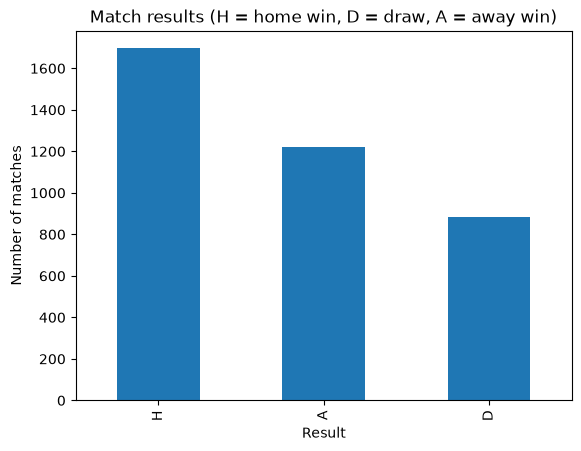

In [62]:
df['FTR'].value_counts().plot(kind='bar')  #use results of W/D/A and create a bar chart
plt.title('Match results (H = home win, D = draw, A = away win)') #title
plt.xlabel('Result') #naming results
plt.ylabel('Number of matches') #n matches
plt.show()

- Bar chart is a good option to analyse and compare the frequency that events use to happen in different categories 

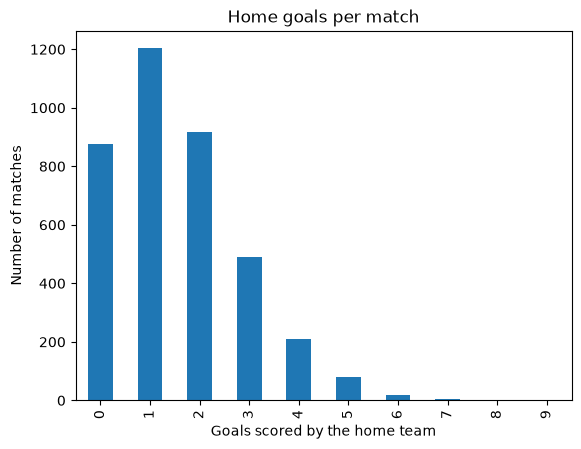

In [63]:
df['FTHG'].value_counts().sort_index().plot(kind='bar') #counting home goals - in a bar chart
plt.title('Home goals per match')
plt.xlabel('Goals scored by the home team')
plt.ylabel('Number of matches')
plt.show()
#Tail on the right because mean is bigger than median and mode. Median = 1, and the most common result is Moda = 1. 
#So all goals after 0 and 1 will make that tail on the right, and there's some, even 9, which is the biggest, but very rare.

- This bar chat show the frequency that happen certain number of goals. The highest bar is 1 so it is the mode and there is a tail to the right because it is not commun to happen matches with many goals.

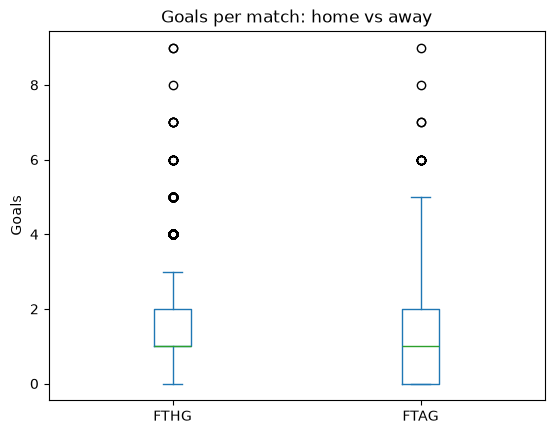

In [64]:
df[['FTHG', 'FTAG']].plot(kind='box')
plt.title('Goals per match: home vs away')
plt.ylabel('Goals')
plt.show()
#FTHG = MEDIAN 1 GOAL PER MATCH; HALF PART OF MATCHES IS FROM 1 TO 2 GOALS PER MATCH; LINE MAX IS THE VALUE THAT IS IN MAX 1,5 x IQR above The box = 0 TO 3.
#FTAG = MEDIAN 1 GOAL PER MATCH; HALF PART OF MATCHES IS FROM 0 TO 2 GOALS PER MATCH; LINE MAX IS VALUE 1,5 X IQR = 0 TO 5.
#The points after box is Outliers, that ones which is not common to happen. Like many goals per match.

- Boxplot is a good option because it shows the difference between home and aways goals in a way that is very easy to identify the outliers.
- While is very commun happen in FTHG 1 to 2 goals, the most commun in FTAG is 0 to 2. 

In [65]:
print(df['FTHG'].quantile([0.25, 0.50, 0.75, 0.90])) # Percentiles (25, 50, 75 and 90 percent)
#number of goals that don't pass 25%, 50%, 75% and 90% of the matches.(Teams use to make less goals than this value)
IntQuant = df['FTHG'].quantile(0.75) - df['FTHG'].quantile(0.25) # Interquartile range (IQR = Q3 - Q1)
print(IntQuant)

print((df['FTHG'] >= 4).mean() * 100) #Now check the Percentage of matches with 4 or more home goals
(df['FTHG'] >= 4).sum() #Number of matches had 4 goals or more

0.25    1.0
0.50    1.0
0.75    2.0
0.90    3.0
Name: FTHG, dtype: float64
1.0
8.289473684210526


np.int64(315)

- Q1 = 1, Median = 1, Q3 = 2, so IQR = 1, 315 matches have more than 4 home goals = 8,289%

In [66]:
print((df[['HS', 'AS', 'HF']] == 0).sum())

HS    1
AS    1
HF    2
dtype: int64


 - Check how many games had just 0 shots/fouls. If it were many matches, could be a problem. But in this case there are Very few games, so OK.

---------------------------------------------------------------------------------  PART 2  ------------------------------------------------------------------------------------


- Binomial Distribution - To count the number of success in a determined number of tries and there are just 2 outcomes "the same probability"
- n = number of tries - matches / k = number of home wins - success / p = chance of succes in one try
- In this analisys each match has 2 overcome: Win or NotWin (Draw/Away)

[0.0027 0.0218 0.0792 0.1702 0.2401 0.2322 0.156  0.0719 0.0217 0.0039
 0.0003]


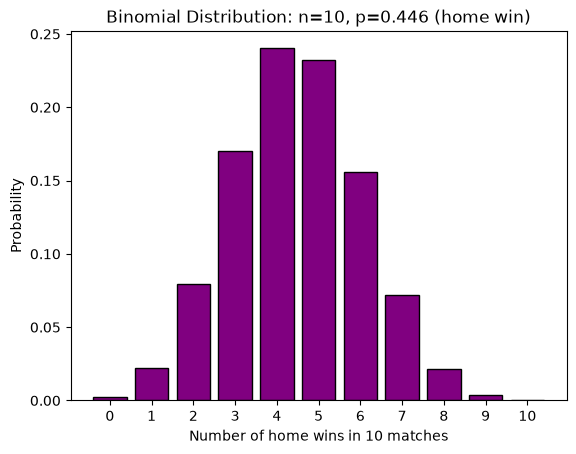

In [67]:
#Parameters 
n = 10                  #number of trials: 10 matches
p = (df['FTR'] == 'H').mean()        #probability of success: home win
k = np.arange(0, n + 1)              #possible numbers of home wins: 0 to 10

# Binomial probability mass function (pmf)
binom_pmf = binom.pmf(k, n, p)
print(binom_pmf.round(4))

# Plot of binomial distribution
plt.bar(k, binom_pmf, color='purple', edgecolor='black')
plt.title(f'Binomial Distribution: n={n}, p={p:.3f} (home win)')
plt.xlabel('Number of home wins in 10 matches')
plt.ylabel('Probability')
plt.xticks(k)
plt.show()

- In 10 home matches - 4 wins has 24% of chance to happen. 
- Remind the total of home win in this dataset is 0.446 = 44.6% of chance; in 10 matches it is 4.46 wins.
- Looks very rare a home team has 0 wins or 10 wins.

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

- Poisson Distribution is used to count how many events happen in a period of time (In this case, in a match)
- Lambda = average number of events (average home goals in each match)/ K = number of events (home goals)/ e = a fixed number.

[2.111e-01 3.284e-01 2.553e-01 1.324e-01 5.150e-02 1.600e-02 4.200e-03
 9.000e-04 2.000e-04 0.000e+00 0.000e+00]


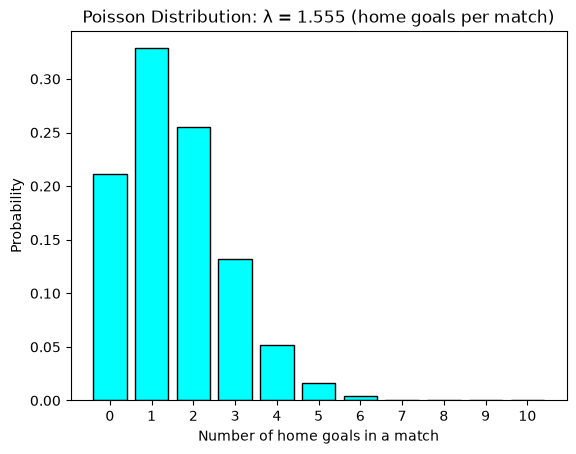

In [68]:
# Parameters
lambda_value = df['FTHG'].mean()      #number of events (home goals) per match
k = np.arange(0, 11)                  #possible number of goals 0 to 10

# Poisson probability mass function pmf
poisson_pmf = poisson.pmf(k, lambda_value)
print(poisson_pmf.round(4))

# Plot the Poisson distribution
plt.bar(k, poisson_pmf, color='cyan', edgecolor='black')
plt.title(f'Poisson Distribution: λ = {lambda_value:.3f} (home goals per match)')
plt.xlabel('Number of home goals in a match')
plt.ylabel('Probability')
plt.xticks(k)
plt.show()

- Most commun result is 1 goal, after 2 goals and 0 goals. 
- There is a tail to the right, it means its not commun a team score many goals in a match

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

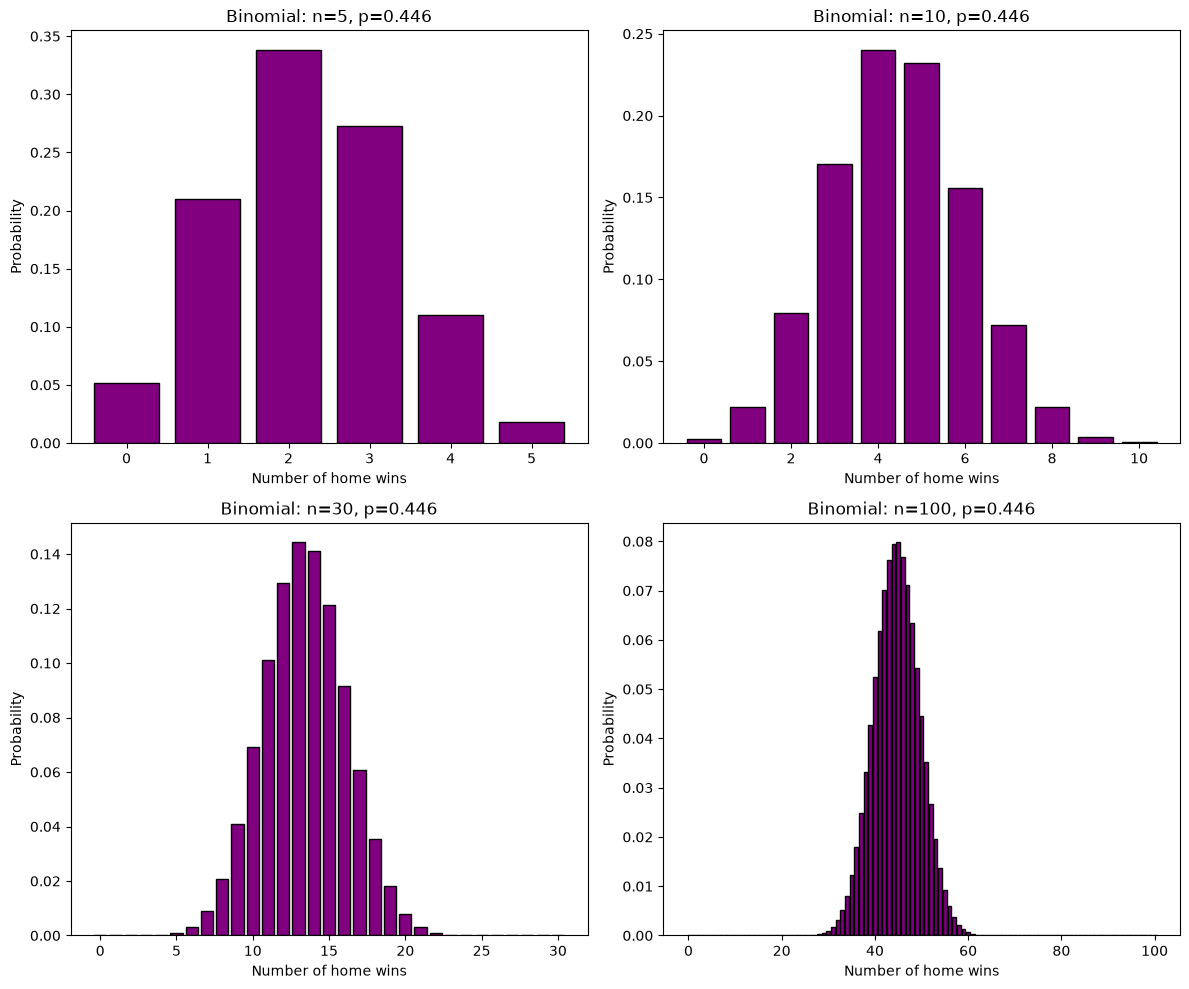

In [69]:
n_values = [5, 10, 30, 100]          # increasing numbers of trials = matches
p = (df['FTR'] == 'H').mean()        # same probability of success like in example 1

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, n in enumerate(n_values):
    ax = axes[i // 2, i % 2]
    k = np.arange(0, n + 1)
    ax.bar(k, binom.pmf(k, n, p), color='purple', edgecolor='black')
    ax.set_title(f'Binomial: n={n}, p={p:.3f}')
    ax.set_xlabel('Number of home wins')
    ax.set_ylabel('Probability')

plt.tight_layout()
plt.show()

- Large Samples Binomial = increasing the analysis by 5, 10, 30 and 100 matches.
- The Graph looks more like a normal distribuction, even more when used much more matches.
- After 30 matches the graph starts looking normal

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

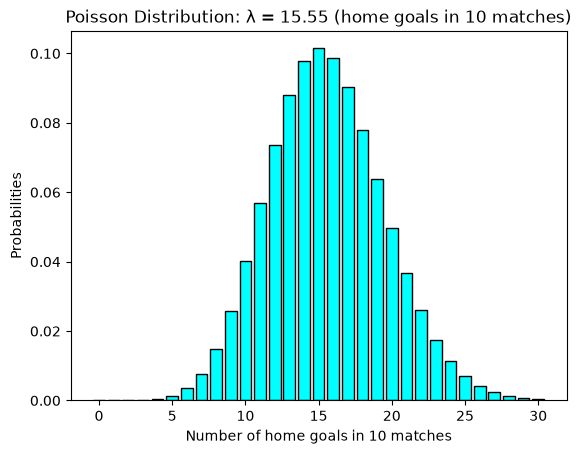

In [70]:
# Parameters for large sample, home goals in 10 matches
lambda_10 = df['FTHG'].mean() * 10   # average home goals in 10 matches
k_10 = np.arange(0, 31)              # possible numbers of goals 0 to 30

# Poisson probability mass function
poisson_pmf_10 = poisson.pmf(k_10, lambda_10)

# Plot the Poisson distribution
plt.bar(k_10, poisson_pmf_10, color='cyan', edgecolor='black')
plt.title(f'Poisson Distribution: λ = {lambda_10:.2f} (home goals in 10 matches)')
plt.xlabel('Number of home goals in 10 matches')
plt.ylabel('Probabilities')
plt.show()

- Peak of chart is in 15 goals. Similar effect that happens with binomial. How bigger are the Matches analysed more the graph looks like a normal distribution.

---------------------------------------------------------------------------------  PART 3  ------------------------------------------------------------------------------------

- For a normal distribution HS is the best option. Because the mean is very high, almost 14, and there are 0 to 37 values. It behave as continuous variable. Mean and Median is very close, it seems as a symmetric distribution. Impossible to use Goals in this case because the matches tend to have just 0, 1 or 2 goals.



13.867105263157894 5.6855822736500325 0.6045215526461797


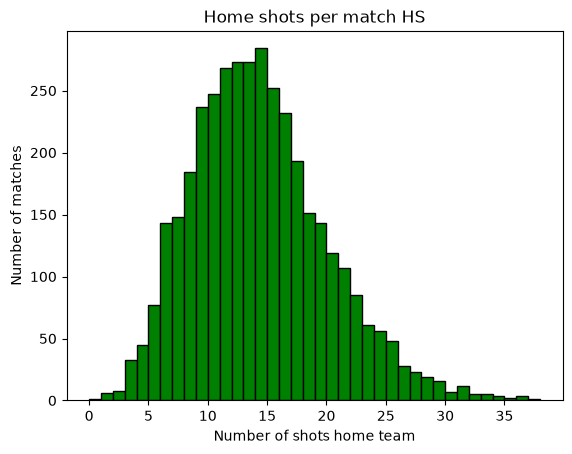

In [71]:
#Normal Distribution HS
mean_hs = df['HS'].mean()     # centre of distribution
std_hs = df['HS'].std()       # spread of distribution
print(mean_hs, std_hs, df['HS'].skew())

#Plot distribution HS
plt.hist(df['HS'], bins=range(0, 39), color='green', edgecolor='black')
plt.title('Home shots per match HS')
plt.xlabel('Number of shots home team')
plt.ylabel('Number of matches')
plt.show()

- Home team tends to score 14 goals for each match, as average where it is the peak. There is a tail longer on the right because few matches had more than 30 shots, and that's why the skewness 0.60 show this.

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [72]:
#Normal model= probabilities below, above, within 1 standard deviation
probability_under = stats.norm.cdf(x=mean_hs - std_hs, loc=mean_hs, scale=std_hs)
probability_over = 1 - stats.norm.cdf(x=mean_hs + std_hs, loc=mean_hs, scale=std_hs)
between_probability = 1 - (probability_under + probability_over)
print(probability_under, probability_over, between_probability)

# Real data= Similar proportions in the dataset
real_under = (df['HS'] < mean_hs - std_hs).mean()
real_over = (df['HS'] > mean_hs + std_hs).mean()
real_between = 1 - (real_under + real_over)
print(real_under, real_over, real_between)

0.15865525393145707 0.15865525393145707 0.6826894921370859
0.16973684210526316 0.15842105263157893 0.6718421052631579


- Normal works well in this case of home shots, a close value 67% when the rule tells around 68% 

In [73]:
#Real data= proportion of matches in 2 and 3 standard deviations of the mean
within_2 = df['HS'].between(mean_hs - 2*std_hs, mean_hs + 2*std_hs).mean()
within_3 = df['HS'].between(mean_hs - 3*std_hs, mean_hs + 3*std_hs).mean()
print(within_2, within_3)

#Porportion of matches in each tail in addition 2 standard deviations
print((df['HS'] < mean_hs - 2*std_hs).mean(), (df['HS'] > mean_hs + 2*std_hs).mean())


0.9628947368421052 0.9913157894736843
0.003947368421052632 0.03315789473684211


- 95% of the matches has to be between 3 and 25 shots, in this case it is 96%. In a perfect normal distribution the ends would be equal but in this case just 0.39% matches has 2 or less shots while many shots, more than 26 happen in 3.3%. Shots can not go under 0 but they can happen many times.

---------------------------------------------------------------------------------  PART 4  ------------------------------------------------------------------------------------

In [74]:
print(df[['FTHG', 'HS']].skew())

FTHG    0.919517
HS      0.604522
dtype: float64


The FTHG = 0.91 it is close to 1, so the chart is very skewed. The HS is 0.6, which it is a little skewed.
Goals chart is much more skewed than Shot chart, so Shots fits more than goals in a Normal distribution.

In [75]:
# Probability of a negative value assuming each variable were Normal
print(stats.norm.cdf(0, loc=df['FTHG'].mean(), scale=df['FTHG'].std()))   # home goals
print(stats.norm.cdf(0, loc=mean_hs, scale=std_hs))                       # home shots

0.11815969518864577
0.007364091303539557


- For goals normal would be very wrong, because is impossible 11.8% negative goals, but for Shots it is just 0.7% a small value.

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Each distribution is used for one type of data.

Binomial= Used for yes or not and in this case it was used just for Home Team Wins or Home Does Not Wins.
Poisson= Used for count how many times some event happens and in this case it was used in Home Goals per match.
Normal= Used for data with many values wich looks like a bell shape and it was used for Home Shots per match.

The FTR = draw and Away Win was combined and it means Home Does not Win. So there is just two outcome like Binomial require. Home = 44,6% of wins. 
The FTHG = In poisson mean and variance has to be similar, and in this case it is 1.56 and 1.72. 
The HS = The mean is high and close to median, asymmetry is moderate like 0.6, that's why the chart seems as normal.

In the case of short samples, the normal distribution can not be used, because the rule is 5 or more wins to the shape be like normal , but in this case the expected number is smaller = 4.46. 
But normal can be used for huge samples. For instance, 30 matches or more in Binomial and 10 matches or more in Poisson the charts approximate a Normal shape.

How bigger is the sample, more a distribution will look like a Normal shape.